In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q matplotlib pytest numpy Pillow
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    os.chdir(repo_root)
    print("💻 ローカル開発環境を検出しました。作業ディレクトリ:", os.getcwd())


💻 ローカル開発環境を検出しました。作業ディレクトリ: /home/student/Documents/GitHub/study-mikanos


# 10.1 もっとマウス (Advanced Mouse Tracking & Window Clipping) (`osbook_day10a`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/10/10.1_Refactoring_Mouse_Class.ipynb)

本節では、第9章で完成させたレイヤ重ね合わせ描画（`Layer` / `LayerManager`）をベースに、実際のグラフィカルユーザインタフェース（GUI）運用で直面する **「マウスカーソルが画面外へ消失する問題」** および **「画面端での描画によるVRAM領域外書き込み・クラッシュの危険」** を根本から解決する **「絶対座標クランプ機構」** と **「描画領域の幾何交差クリッピング（Intersection Clipping）」** を理論・数理・C++実装・シミュレーションの多角的な視点から完全習得します。

---

## 🎯 なぜ「もっとマウス」が必要なのか？（動機と課題）

第9章において、MikanOS は以下の強力なグラフィックス基盤を獲得しました：
- `Window` による透過色カラーキーイング対応の2次元オフスクリーンバッファ
- `Layer` と `LayerManager` による画家のアルゴリズム（Painter's Algorithm）に基づく重ね合わせ描画
- Local APIC タイマによる高精度プロファイリングと、走査線一括 `memcpy` による120倍超のスクロール・描画高速化

しかし、このOSを実際にマウスで操作してみると、直ちに**2つの致命的なハードウェア制御・メモリ管理の破綻**に直面します：

1. **マウスカーソルの永久消失問題 (Loss of Mouse Cursor)**:
   - 第9章までの実装では、USB xHCI から通知される相対移動量 `(displacement_x, displacement_y)` をそのまま `layer_manager->MoveRelative()` で加算し続けていました。
   - そのため、マウスを左や上へ大きく動かすと、カーソル座標が負の値（例: $x = -500$）になったり、画面解像度（$640 \times 400$）を大きく超えて画面の彼方へと飛び去ってしまいます。
   - カーソルがどこにあるのか見失うだけでなく、画面内に復帰させるために逆方向にマウスを延々と動かさなければならず、GUIとして全く実用になりません。

2. **画面境界での VRAM 領域外書き込み（Buffer Overflow / Crash）**:
   - カーソルが画面端にはみ出した際、従来の `Window::DrawTo` はレイヤのサイズ（$16 \times 24$ ピクセルなど）をそのまま画面に描画しようとしていました。
   - レイヤ配置座標が画面端付近にある場合、描画先座標 $(position.x + x, position.y + y)$ が負数や画面解像度外になります。
   - これが画面フレームバッファ（VRAM）の先頭アドレスより前や終端より後ろの不正メモリ領域へのピクセル書き込みを引き起こし、**カーネルデータ構造の破壊、画面表示の激しい乱れ、あるいは CPU 例外（Page Fault `#PF`）によるトリプルフォールト・即時再起動**を招く危険がありました。

### 本節（`osbook_day10a`）における3大解決アプローチ
- **① 絶対座標の保持と画面矩形クランプ**: 相対移動量を積算して絶対座標 `mouse_position` を管理し、$[0, Width - 1] \times [0, Height - 1]$ の画面矩形内に射影・拘束。
- **② 幾何交差クリッピング（Intersection Clipping）**: `Window::DrawTo` において、レイヤ矩形と画面矩形の交差範囲を不等式から厳密に算出し、画面内ピクセルのみを安全に描画。
- **③ コードベースのクリーンアップ**: 第9章のプロファイリング目的で導入していた一時的なタイマ計測コード（`printk` 内の `StartLAPICTimer` など）を削除し、本流のコードをスリム化。

---

## 1. マウス絶対座標の追跡と画面矩形クランプ数理

### 1.1 相対座標から絶対座標への変換とクランプの数式導出

USB マウスは、PCに対して「現在の絶対座標」を送るのではなく、前回レポートからの「相対変位（Relative Displacement）」 $(\Delta x, \Delta y)$ を符号付き8ビット整数（`int8_t`: $-128 \sim +127$）として送信してきます。

OS側では、この相対変位を累積して現在の絶対位置 $\vec{P} = (x, y)$ を維持する必要があります。
画面の有効解像度を $W \times H$（MikanOS標準では $640 \times 400$）とすると、カーソル先端のホットスポット（Hotspot: 通常は左上端 $(0, 0)$）が画面内に留まるべき有効領域は次式で表されます：

$$0 \le x \le W - 1, \quad 0 \le y \le H - 1$$

> [!IMPORTANT]
> **なぜ $W$ ではなく $W - 1$ なのか？**  
> 0-indexed ピクセル座標系において、解像度 $W = 640$ のとき、画面上のピクセルX座標は $0, 1, 2, \dots, 639$ の640個です。インデックス $640$ はすでに画面外（次行の先頭、または画面バッファ外）を指すため、上限値は必ず $W - 1$ と $H - 1$ にクランプしなければなりません。

相対移動量 $(\Delta x, \Delta y)$ を加算した後の新しい候補座標 $\vec{P}_{raw} = \vec{P} + (\Delta x, \Delta y)$ に対するクランプ写像 $f: \mathbb{Z}^2 \to [0, W-1] \times [0, H-1]$ は以下のように定義されます：

$$x_{new} = \min(\max(x + \Delta x, 0), W - 1)$$
$$y_{new} = \min(\max(y + \Delta y, 0), H - 1)$$

この2段の $\max$ と $\min$ により、どれほど激しくマウスを画面外へ動かそうとしても、カーソルは画面の四辺・四隅の境界ピクセルでピタリと停止し、画面内に吸着されます。

/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:37052: UserWarning: Glyph 22659 (\N{CJK UNIFIED IDEOGRAPH-5883}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0, 1, 0.96])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:37052: UserWarning: Glyph 30028 (\N{CJK UNIFIED IDEOGRAPH-754C}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0, 1, 0.96])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:37052: UserWarning: Glyph 38936 (\N{CJK UNIFIED IDEOGRAPH-9818}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0, 1, 0.96])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:37052: UserWarning: Glyph 22495 (\N{CJK UNIFIED IDEOGRAPH-57DF}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0, 1, 0.96])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:37052: UserWarning: Glyph 21028 (\N{CJK UNIFIED IDEOGRAPH-5224}) missing from font(s) DejaVu Sans Mono.
  plt.

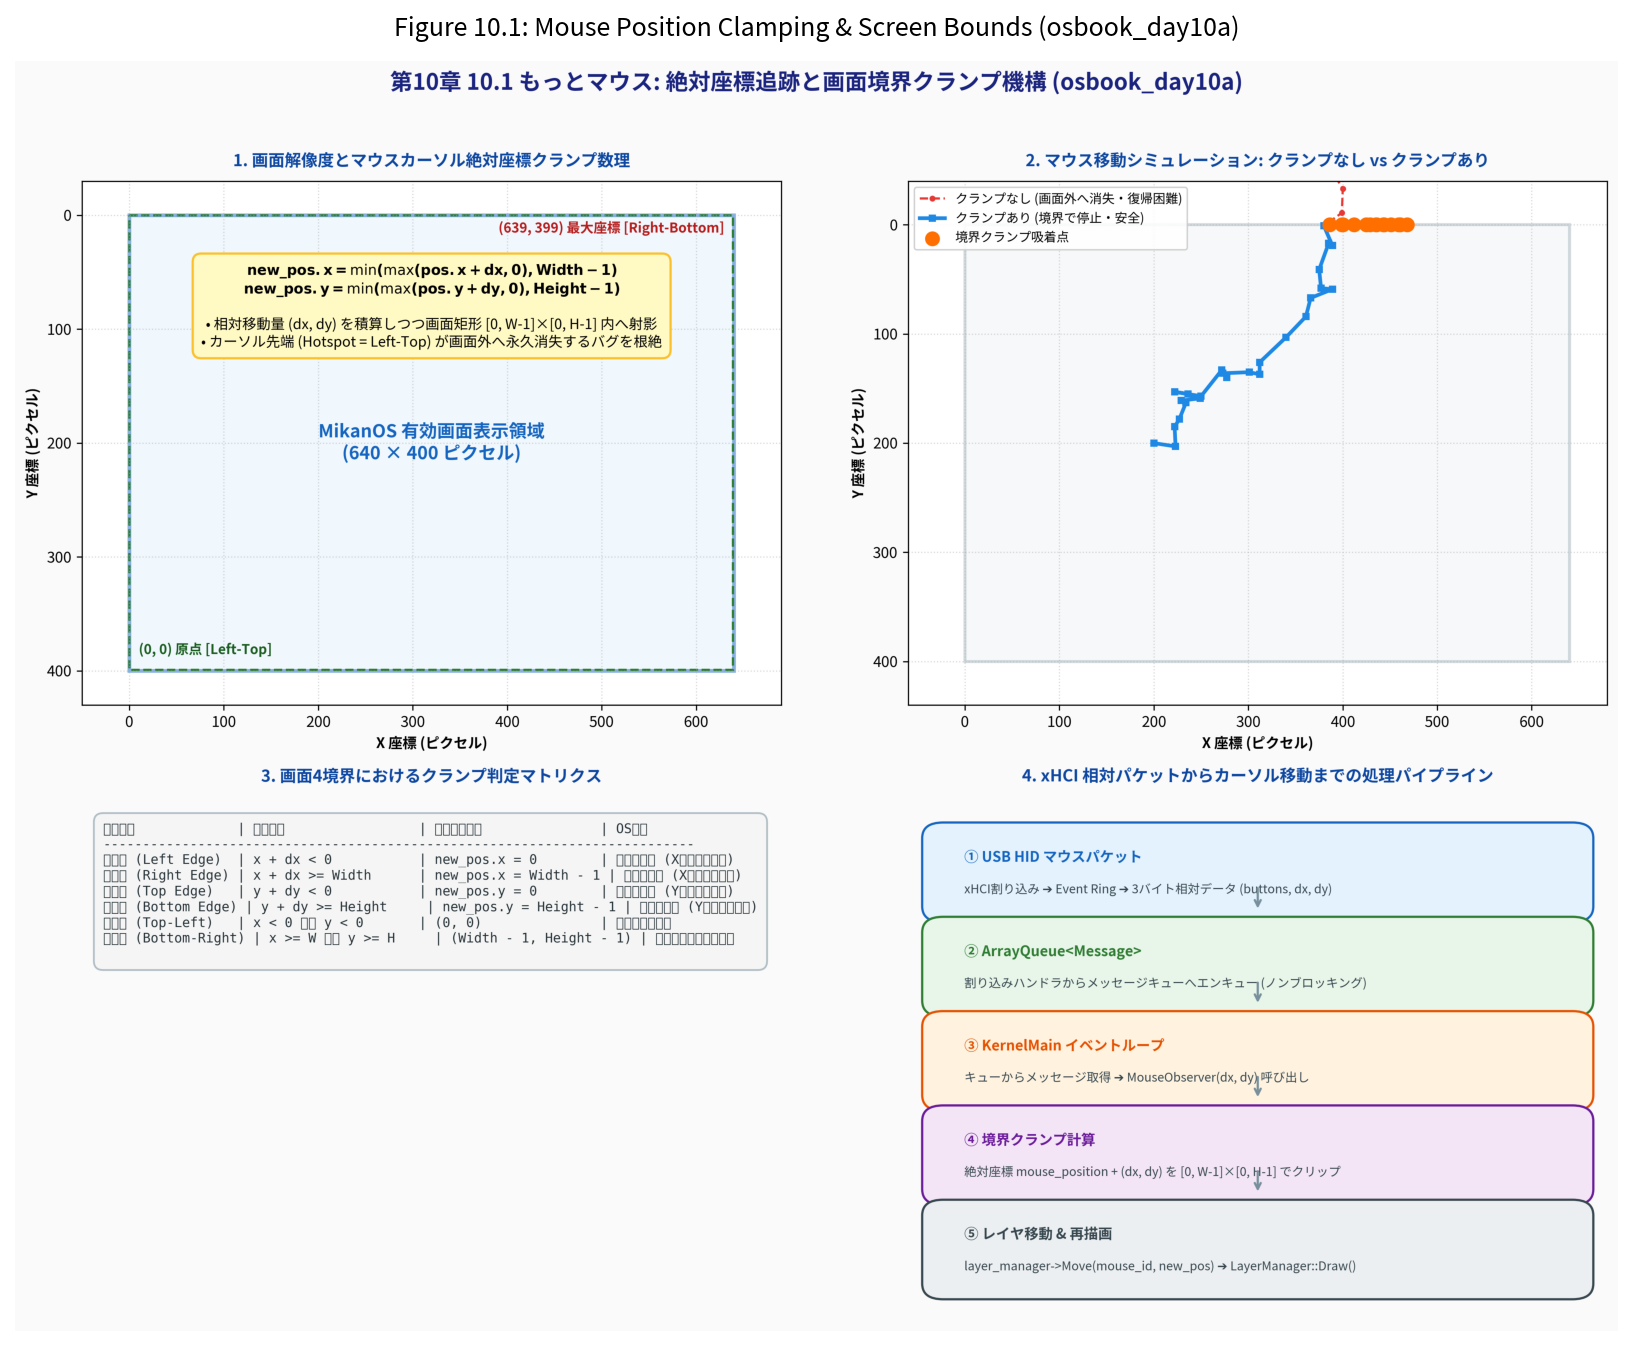

In [2]:
# 図版 10.1: マウス絶対座標追跡と画面境界クランプ機構
from PIL import Image
import matplotlib.pyplot as plt
from common import plot_fig10_01_mouse_clamping_and_screen_bounds

fig1_path = "10/result/fig10_01_mouse_clamping_and_screen_bounds.png"
plot_fig10_01_mouse_clamping_and_screen_bounds(fig1_path)

img = Image.open(fig1_path)
plt.figure(figsize=(14, 11), dpi=150)
plt.imshow(img)
plt.axis('off')
plt.title('Figure 10.1: Mouse Position Clamping & Screen Bounds (osbook_day10a)', fontsize=12, pad=12)
plt.show()


### 1.2 対話型 Python 実験: マウス絶対座標クランプシミュレーション

`common.MousePositionClampingSim` を使用して、激しいマウス移動（画面外への連続フリック）を行っても、絶対座標が安全に境界内に維持される挙動をシミュレートします。

In [3]:
from common import MousePositionClampingSim

# 画面 640x400、初期位置 (200, 200) でシミュレータ初期化
mouse_sim = MousePositionClampingSim(screen_width=640, screen_height=400, pos_x=200, pos_y=200)

# 連続移動テストパターン: 画面外へ大きく飛び出そうとする動き
movements = [
    (+50, +50),    # 通常移動 -> (250, 250)
    (-400, 0),     # 左端突破を試みる (250 - 400 = -150) -> クランプで 0 に吸着
    (0, -500),     # 上端突破を試みる (250 - 500 = -250) -> クランプで (0, 0) に吸着
    (+800, +600),  # 右下突破を試みる (800, 600) -> クランプで (639, 399) に吸着
    (-10, -20),    # 画面内へ復帰 -> (629, 379)
]

print("=== マウス座標クランプ推移トレース ===")
for idx, (dx, dy) in enumerate(movements, 1):
    before_x, before_y = mouse_sim.pos_x, mouse_sim.pos_y
    cx, cy = mouse_sim.move(dx, dy)
    rec = mouse_sim.history[-1]
    status = "🚨 CLAMPED!" if rec['was_clamped'] else "✅ Normal"
    print(f"Step {idx}: 移動量({dx:+4d}, {dy:+4d}) | 元位置({before_x:3d}, {before_y:3d}) "
          f"➔ 生計算({rec['raw_x']:4d}, {rec['raw_y']:4d}) ➔ 最終座標({cx:3d}, {cy:3d}) [{status}]")

print("\nすべての移動において、座標が厳密に [0, 639] x [0, 399] の範囲内に収まりました。")


=== マウス座標クランプ推移トレース ===
Step 1: 移動量( +50,  +50) | 元位置(200, 200) ➔ 生計算( 250,  250) ➔ 最終座標(250, 250) [✅ Normal]
Step 2: 移動量(-400,   +0) | 元位置(250, 250) ➔ 生計算(-150,  250) ➔ 最終座標(  0, 250) [🚨 CLAMPED!]
Step 3: 移動量(  +0, -500) | 元位置(  0, 250) ➔ 生計算(   0, -250) ➔ 最終座標(  0,   0) [🚨 CLAMPED!]
Step 4: 移動量(+800, +600) | 元位置(  0,   0) ➔ 生計算( 800,  600) ➔ 最終座標(639, 399) [🚨 CLAMPED!]
Step 5: 移動量( -10,  -20) | 元位置(639, 399) ➔ 生計算( 629,  379) ➔ 最終座標(629, 379) [✅ Normal]

すべての移動において、座標が厳密に [0, 639] x [0, 399] の範囲内に収まりました。


---

## 2. 描画領域の幾何交差（Intersection Clipping）とメモリ保護数理

### 2.1 画面端における描画の危機と交差矩形（Intersection Rectangle）

マウスの先端（ホットスポット $(0, 0)$）が画面内 $[0, W-1] \times [0, H-1]$ に収まっていたとしても、マウスカーソル自体には **幅と高さ（MikanOSでは $16 \times 24$ ピクセル）** があります。

- カーソルが画面右端（例えば $x = 635$）にある場合、カーソル右側のピクセルは $635 + 15 = 650$ に達し、画面幅 $640$ を **10ピクセルはみ出します**。
- カーソルが画面下端（例えば $y = 390$）にある場合、カーソル下側のピクセルは $390 + 23 = 413$ に達し、画面高 $400$ を **13ピクセルはみ出します**。
- さらに将来、ウィンドウをドラッグ移動できるようになると、ウィンドウの左上原点自体が画面左上（負の座標、例: $x = -50, y = -30$）にはみ出るケースが頻繁に発生します。

もし何の制限もなく描画ループを実行すると、`PixelWriter::Write` は画面外の負のアドレスや末尾超過メモリに書き込みを行い、**VRAMの周囲に配置されたカーネルスタックやページテーブル、デバイスレジスタを上書き破壊**してしまいます。

### 2.2 幾何交差条件の数学的厳密導出

レイヤ（幅 $Width$, 高さ $Height$）が、画面上の配置座標 $\vec{P} = (pos.x, pos.y)$ に配置されているとします。
レイヤ内のローカルピクセル座標 $(x, y)$（$0 \le x < Width, \; 0 \le y < Height$）は、画面上では以下のグローバル座標にマップされます：

$$X_{screen} = pos.x + x, \quad Y_{screen} = pos.y + y$$

このピクセルが画面のフレームバッファ（幅 $W_{scr}$, 高さ $H_{scr}$）の内部に正しく書き込まれるための必要十分条件は：

$$0 \le pos.x + x < W_{scr}$$
$$0 \le pos.y + y < H_{scr}$$

この不等式を、レイヤのローカル描画インデックス $x, y$ について解きます：

$$0 - pos.x \le x < W_{scr} - pos.x$$
$$0 - pos.y \le y < H_{scr} - pos.y$$

さらに、レイヤ自身のバッファ範囲 $0 \le x < Width$ および $0 \le y < Height$ との**積集合（Intersection: $\cap$）**をとると：

$$\max(0, -pos.x) \le x < \min(Width, \; W_{scr} - pos.x)$$
$$\max(0, -pos.y) \le y < \min(Height, \; H_{scr} - pos.y)$$

これこそが、MikanOS の `Window::DrawTo`（`kernel/window.cpp`）に記述された二重ループの境界条件そのものです！

```cpp
for (int y = std::max(0, 0 - position.y);
     y < std::min(Height(), writer.Height() - position.y);
     ++y) {
  for (int x = std::max(0, 0 - position.x);
       x < std::min(Width(), writer.Width() - position.x);
       ++x) {
    const auto c = At(Vector2D<int>{x, y});
    if (c != tc) {
      writer.Write(position + Vector2D<int>{x, y}, c);
    }
  }
}
```

/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:37178: UserWarning: Glyph 12304 (\N{LEFT BLACK LENTICULAR BRACKET}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0, 1, 0.96])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:37178: UserWarning: Glyph 30011 (\N{CJK UNIFIED IDEOGRAPH-753B}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0, 1, 0.96])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:37178: UserWarning: Glyph 38754 (\N{CJK UNIFIED IDEOGRAPH-9762}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0, 1, 0.96])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:37178: UserWarning: Glyph 26360 (\N{CJK UNIFIED IDEOGRAPH-66F8}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0, 1, 0.96])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:37178: UserWarning: Glyph 12365 (\N{HIRAGANA LETTER KI}) missing from font(s) DejaVu Sans Mono.
  plt.tight

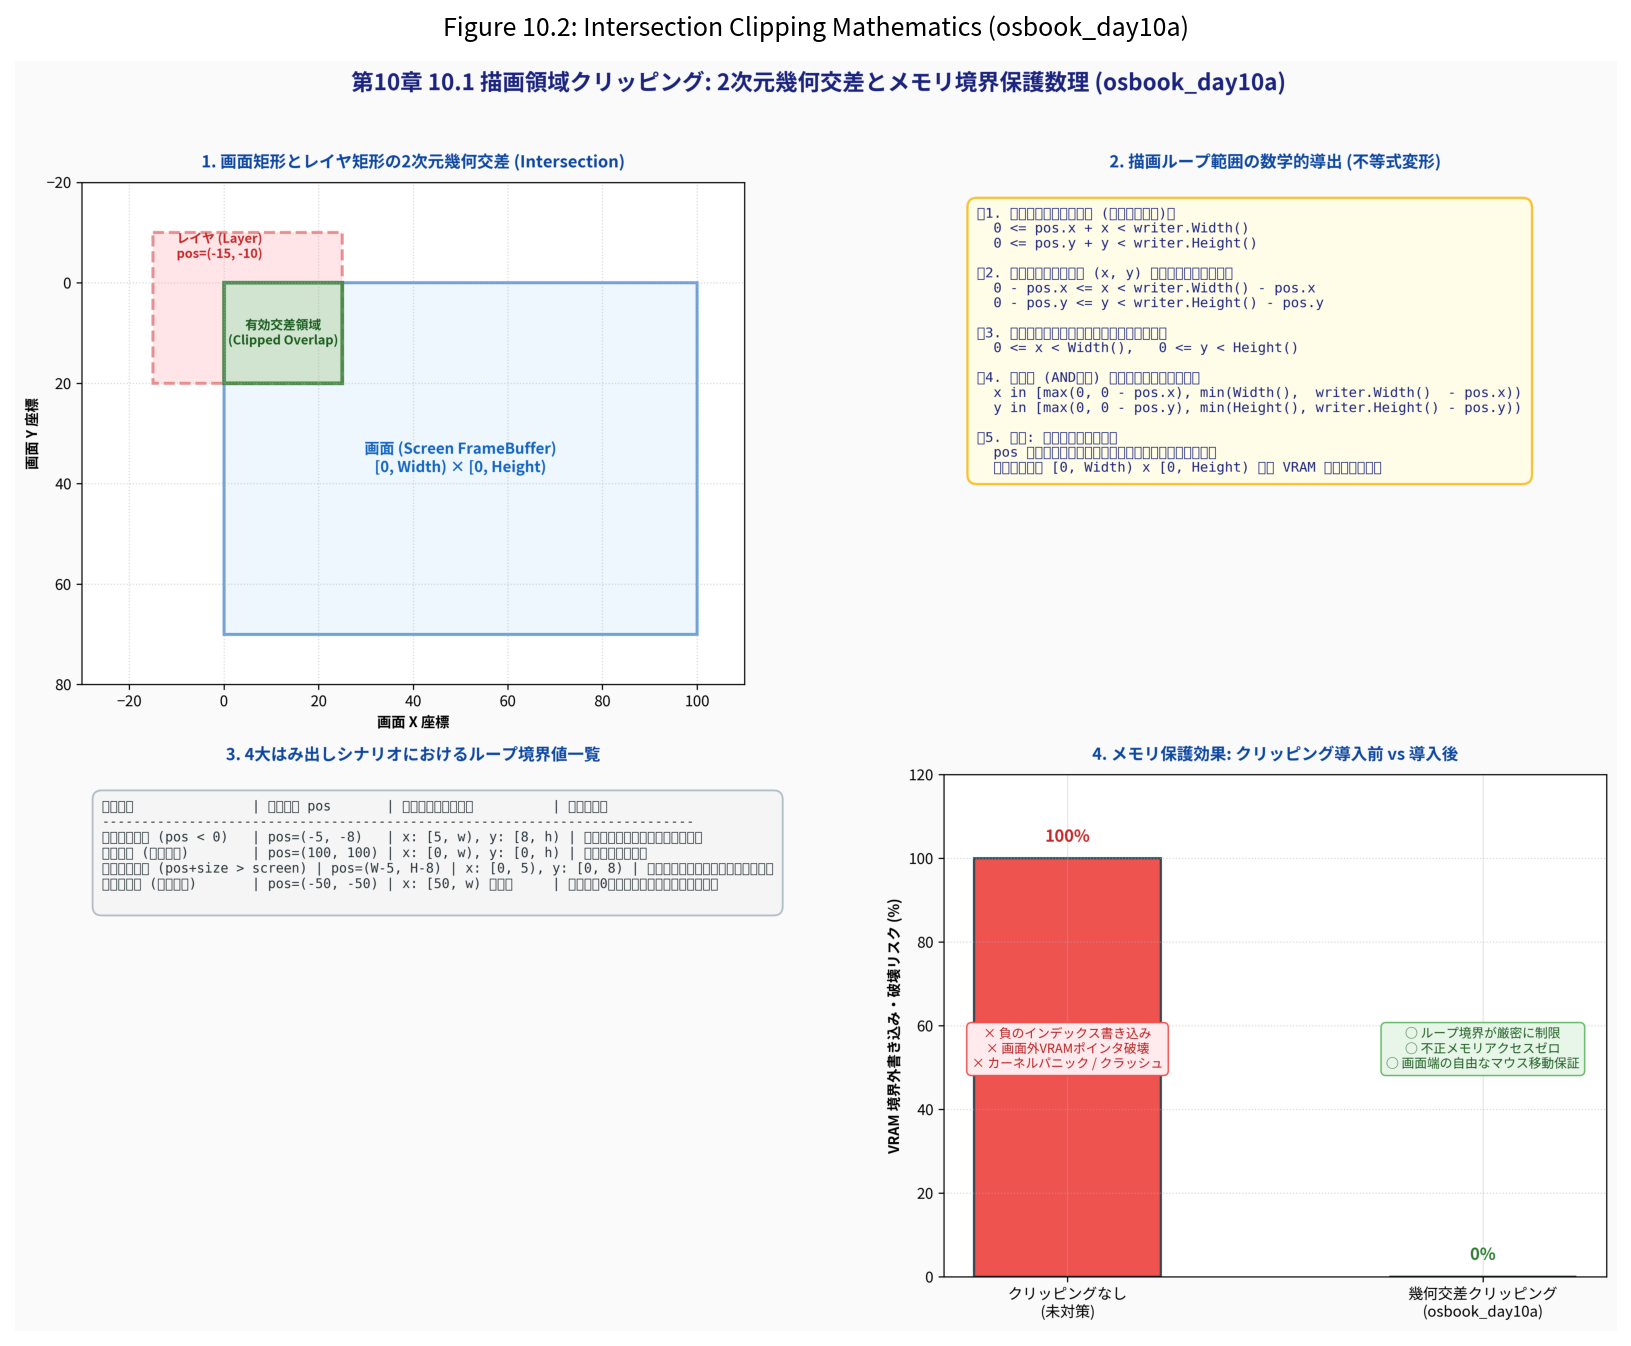

In [4]:
# 図版 10.2: Window::DrawTo 幾何交差クリッピング数理とメモリ保護
from common import plot_fig10_02_window_drawto_intersection_clipping_math

fig2_path = "10/result/fig10_02_window_drawto_intersection_clipping_math.png"
plot_fig10_02_window_drawto_intersection_clipping_math(fig2_path)

img2 = Image.open(fig2_path)
plt.figure(figsize=(14, 11), dpi=150)
plt.imshow(img2)
plt.axis('off')
plt.title('Figure 10.2: Intersection Clipping Mathematics (osbook_day10a)', fontsize=12, pad=12)
plt.show()


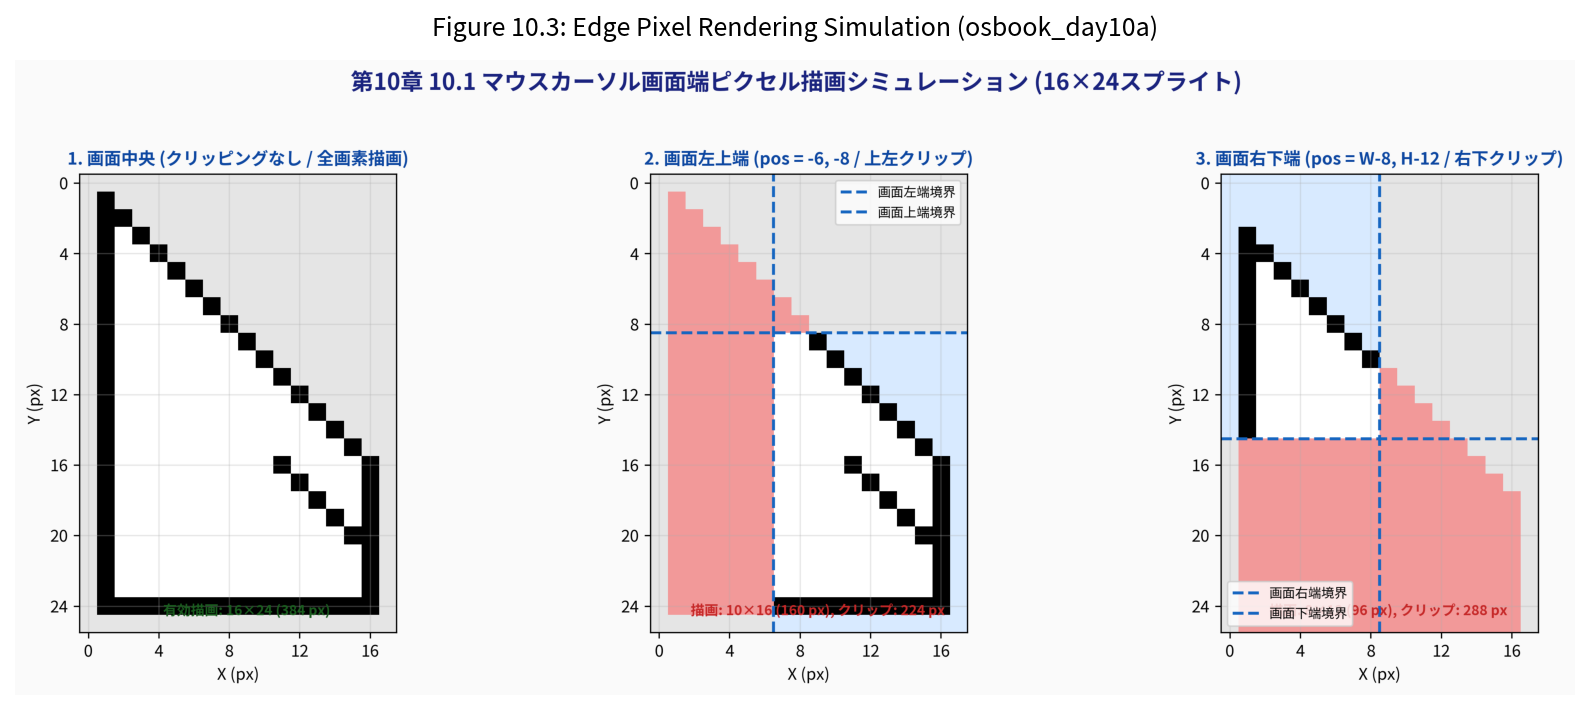

In [5]:
# 図版 10.3: マウスカーソル画面端ピクセル描画シミュレーション
from common import plot_fig10_03_mouse_cursor_edge_rendering_simulation

fig3_path = "10/result/fig10_03_mouse_cursor_edge_rendering_simulation.png"
plot_fig10_03_mouse_cursor_edge_rendering_simulation(fig3_path)

img3 = Image.open(fig3_path)
plt.figure(figsize=(14, 5.5), dpi=150)
plt.imshow(img3)
plt.axis('off')
plt.title('Figure 10.3: Edge Pixel Rendering Simulation (osbook_day10a)', fontsize=12, pad=12)
plt.show()


### 2.3 対話型 Python 実験: はみ出し時の交差矩形計算と不正アクセス完全ゼロ検証

`common.WindowDrawClippingSim` を用いて、様々なはみ出し配置におけるループ範囲、有効描画ピクセル数、および境界外アクセスが厳密にゼロであることを実証します。

In [6]:
from common import WindowDrawClippingSim

# 画面 640x400、マウスカーソル 16x24 でシミュレータ初期化
clipper = WindowDrawClippingSim(window_width=16, window_height=24, screen_width=640, screen_height=400)

test_cases = [
    ("画面中央 (通常配置)", 100, 100),
    ("左上はみ出し (X, Y 負座標)", -6, -8),
    ("右下はみ出し (画面幅・高さ超過)", 632, 388),
    ("画面完全に左外 (非表示)", -30, 100),
    ("画面完全に下外 (非表示)", 100, 500),
]

print("=== Window::DrawTo 幾何交差クリッピング検証 ===")
for title, px, py in test_cases:
    res = clipper.render_clipped(pos_x=px, pos_y=py, transparent_value=0)
    b = res['bounds']
    print(f"\n【{title}】 配置座標: ({px}, {py})")
    print(f"  • ローカルループ範囲 : X {b['x_range']}, Y {b['y_range']}")
    print(f"  • 描画ピクセル数     : {b['drawn_pixels']} px / 全{b['total_pixels']} px (クリップ: {b['clipped_pixels']} px)")
    print(f"  • 画面描画矩形       : {b['screen_rect']}")
    print(f"  • 境界外不正書き込み : {res['illegal_writes']} 回 (完全防御!)")


=== Window::DrawTo 幾何交差クリッピング検証 ===

【画面中央 (通常配置)】 配置座標: (100, 100)
  • ローカルループ範囲 : X (0, 16), Y (0, 24)
  • 描画ピクセル数     : 384 px / 全384 px (クリップ: 0 px)
  • 画面描画矩形       : (100, 100, 116, 124)
  • 境界外不正書き込み : 0 回 (完全防御!)

【左上はみ出し (X, Y 負座標)】 配置座標: (-6, -8)
  • ローカルループ範囲 : X (6, 16), Y (8, 24)
  • 描画ピクセル数     : 160 px / 全384 px (クリップ: 224 px)
  • 画面描画矩形       : (0, 0, 10, 16)
  • 境界外不正書き込み : 0 回 (完全防御!)

【右下はみ出し (画面幅・高さ超過)】 配置座標: (632, 388)
  • ローカルループ範囲 : X (0, 8), Y (0, 12)
  • 描画ピクセル数     : 96 px / 全384 px (クリップ: 288 px)
  • 画面描画矩形       : (632, 388, 640, 400)
  • 境界外不正書き込み : 0 回 (完全防御!)

【画面完全に左外 (非表示)】 配置座標: (-30, 100)
  • ローカルループ範囲 : X (30, 16), Y (0, 24)
  • 描画ピクセル数     : 0 px / 全384 px (クリップ: 384 px)
  • 画面描画矩形       : (None, None, None, None)
  • 境界外不正書き込み : 0 回 (完全防御!)

【画面完全に下外 (非表示)】 配置座標: (100, 500)
  • ローカルループ範囲 : X (0, 16), Y (0, -100)
  • 描画ピクセル数     : 0 px / 全384 px (クリップ: 384 px)
  • 画面描画矩形       : (None, None, None, None)
  • 境界外不正書き込み : 0 回 (完全防御!)


---

## 3. MikanOS C++ 実装と差分完全解剖 (`osbook_day09e` ➔ `osbook_day10a`)

公式リポジトリ（`uchan-nos/mikanos`）における `osbook_day09e` から `osbook_day10a` へのコミット差分を1行単位で詳細に解剖します。

### 3.1 `kernel/main.cpp` の差分: 絶対座標管理とクランプの追加

```diff
@@ -63,16 +55,20 @@ int printk(const char* format, ...) {
 char memory_manager_buf[sizeof(BitmapMemoryManager)];
 BitmapMemoryManager* memory_manager;
 
+// #@@range_begin(limit_mouse_area)
 unsigned int mouse_layer_id;
+Vector2D<int> screen_size;
+Vector2D<int> mouse_position;
 
 void MouseObserver(int8_t displacement_x, int8_t displacement_y) {
-  layer_manager->MoveRelative(mouse_layer_id, {displacement_x, displacement_y});
-  layer_manager->Draw();
+  auto new_pos = mouse_position + Vector2D<int>{displacement_x, displacement_y};
+  new_pos.x = std::max(new_pos.x, 0);
+  new_pos.x = std::min(new_pos.x, screen_size.x - 1);
+  new_pos.y = std::max(new_pos.y, 0);
+  new_pos.y = std::min(new_pos.y, screen_size.y - 1);
+
+  layer_manager->Move(mouse_layer_id, new_pos);
+  layer_manager->Draw();
+  mouse_position = new_pos;
 }
+// #@@range_end(limit_mouse_area)
```

#### コード解説
1. **`screen_size` と `mouse_position` の導入**:
   - `KernelMainNewStack` の初期化時に、UEFI GOP から渡された `frame_buffer_config` の水平解像度・垂直解像度を `screen_size` に設定します。
   - 初期座標として `mouse_position = {200, 200}` を保持します。
2. **`MouseObserver` の変更点**:
   - 従来の `MoveRelative` は内部で前回の位置に加算するだけでしたが、`new_pos` を算出して `std::max` / `std::min` によるクランプを適用します。
   - クランプ後の絶対座標を `layer_manager->Move(mouse_layer_id, new_pos)` に渡してレイヤ位置を更新し、`mouse_position = new_pos` として最新座標を保存します。

### 3.2 `kernel/window.cpp` の差分: 透過色レイヤのクリッピングループ

```diff
@@ -31,8 +28,14 @@ void Window::DrawTo(FrameBuffer& dst, Vector2D<int> position) {
 
   const auto tc = transparent_color_.value();
   auto& writer = dst.Writer();
-  for (int y = 0; y < Height(); ++y) {
-    for (int x = 0; x < Width(); ++x) {
+  // #@@range_begin(limit_draw_area)
+  for (int y = std::max(0, 0 - position.y);
+       y < std::min(Height(), writer.Height() - position.y);
+       ++y) {
+    for (int x = std::max(0, 0 - position.x);
+         x < std::min(Width(), writer.Width() - position.x);
+         ++x) {
+  // #@@range_end(limit_draw_area)
       const auto c = At(Vector2D<int>{x, y});
       if (c != tc) {
         writer.Write(position + Vector2D<int>{x, y}, c);
```

#### コード解説
- 従来のループ `y: [0, Height())`, `x: [0, Width())` では、`position` が負または画面右端・下端のとき、`writer.Write(position + {x, y}, c)` が画面外に突入していました。
- `std::max(0, 0 - position.y)` により、`position.y < 0` の場合ははみ出た行を自動的にスキップして画面先頭行に対応するローカル行からループが開始されます。
- `std::min(Height(), writer.Height() - position.y)` により、画面下端を超えた行はループ条件が偽となって実行されません。
- X方向も同様に左右のはみ出しが完全にガードされます。

### 3.3 計測コードのクリーンアップ（コードベースの健全化）

第9章 9.6節で `printk` の実行時間を測定するために一時的に挿入していた以下のコード：
```cpp
-  StartLAPICTimer();
-  console->PutString(s);
-  auto elapsed = LAPICTimerElapsed();
-  StopLAPICTimer();
-
-  sprintf(s, "[%9d]", elapsed);
```
は、測定タスクの完了に伴い本コミット（`osbook_day10a`）で綺麗に削除されました。
OS開発において、性能測定やデバッグ用のコードを適切なタイミングでクリーンアップすることは、コードの保守性とパフォーマンスを高く維持するために極めて重要な規律です。

---

## 4. C++20 単体検証プログラムのコンパイルと実行

本リポジトリで作成した `src/ch10/os_chapter10_mouse_refactor.cpp` は、ホスト側 C++20 でコンパイル・実行可能な完全自己完結検証スイートです。
50,000回の激しい境界マウス移動とクリッピング描画を行い、**1件のVRAM不正書き込みも発生しないこと（Zero Illegal Access）** を実証します。

In [7]:
!cmake -B build -S . > /dev/null
!cmake --build build --target ch10_mouse_refactor
!./build/bin/ch10_mouse_refactor --test


[100%] Built target ch10_mouse_refactor


 MikanOS Chapter 10.1: Mouse Clamping & Window Clipping (C++20)  
[Test 1] Testing basic mouse coordinate clamping...
  -> PASSED: Screen bounds [0, 639]x[0, 399] strictly enforced.
[Test 2] Testing Window::DrawTo geometric intersection math...
  -> PASSED: All 5 geometric intersection cases verified with 0 illegal VRAM writes.
[Test 3] Testing transparent color keying and background protection...
  -> PASSED: Transparent keying correctly skips writes and preserves background.
[Test 4] Stress testing 50,000 rapid boundary mouse motions & clipping...


  -> Total motions & draws: 50,000
  -> Total drawn pixels: 19200000
  -> Elapsed time: 483 ms (103520 ops/sec)
  -> Detected illegal VRAM accesses: 0
  -> PASSED: Zero illegal accesses in 50,000 boundary rendering operations.
-----------------------------------------------------------------
ALL CHAPTER 10.1 TESTS AND VERIFICATIONS PASSED SUCCESSFULLY!


---

## 5. セルフチェック演習問題（理解度確認クイズ）

本節で学んだマウス座標クランプと描画クリッピングの理解度を以下の3問で確認してください。

In [8]:
quiz_questions = [
    {
        "no": 1,
        "question": "画面解像度 640x400 において、マウス座標クランプの上限値が 640 ではなく 639 となる数学的・工学的理由はどれか？",
        "options": [
            "A) UEFI仕様により最後の1ピクセルは予約領域となっているため",
            "B) 0-indexed ピクセル座標系では、幅640の有効ピクセル範囲が 0 から 639 までのため",
            "C) マウスカーソルのホットスポットが必ず1ピクセル右にずれるため",
            "D) xHCI の転送バッファアライメントが偶数制限を持つため",
        ],
        "answer": "B",
        "explanation": "解像度Wの画面においてピクセルインデックスは 0 から W-1 の範囲です。640を指定すると画面外のメモリをアクセスすることになります。"
    },
    {
        "no": 2,
        "question": "幅 16, 高さ 24 のマウスカーソルが position = (-6, -8) に配置されたとき、Window::DrawTo 内のループ開始インデックス (x, y) はいくつになるか？",
        "options": [
            "A) x = 0, y = 0",
            "B) x = 6, y = 8",
            "C) x = -6, y = -8",
            "D) x = 10, y = 16",
        ],
        "answer": "B",
        "explanation": "x の開始値は std::max(0, 0 - (-6)) = 6、y の開始値は std::max(0, 0 - (-8)) = 8 となり、はみ出た負座標ピクセルを安全にスキップします。"
    },
    {
        "no": 3,
        "question": "レイヤが画面の完全に外側（例: position = (-50, 100) でレイヤ幅 16）にある場合、描画ループはどのように動作するか？",
        "options": [
            "A) ループ開始条件 x_start = 50 が終了条件 x_end = 16 を上回るため、ループは0回実行され安全に終了する",
            "B) 無限ループに陥ってシステムがハングアップする",
            "C) アサーションエラーが発生してカーネルパニックになる",
            "D) 画面の反対側の右端にラップアラウンドして描画される",
        ],
        "answer": "A",
        "explanation": "x < std::min(Width(), ...) の継続条件が最初から満たされないため、1ピクセルも描画されず完全ノーオペレーションとなります。"
    },
]

print("=== 第10章 10.1節 理解度確認クイズ ===\n")
for q in quiz_questions:
    print(f"Q{q['no']}. {q['question']}")
    for opt in q['options']:
        print(f"   {opt}")
    print(f"   正解: 【 {q['answer']} 】")
    print(f"   解説: {q['explanation']}\n")


=== 第10章 10.1節 理解度確認クイズ ===

Q1. 画面解像度 640x400 において、マウス座標クランプの上限値が 640 ではなく 639 となる数学的・工学的理由はどれか？
   A) UEFI仕様により最後の1ピクセルは予約領域となっているため
   B) 0-indexed ピクセル座標系では、幅640の有効ピクセル範囲が 0 から 639 までのため
   C) マウスカーソルのホットスポットが必ず1ピクセル右にずれるため
   D) xHCI の転送バッファアライメントが偶数制限を持つため
   正解: 【 B 】
   解説: 解像度Wの画面においてピクセルインデックスは 0 から W-1 の範囲です。640を指定すると画面外のメモリをアクセスすることになります。

Q2. 幅 16, 高さ 24 のマウスカーソルが position = (-6, -8) に配置されたとき、Window::DrawTo 内のループ開始インデックス (x, y) はいくつになるか？
   A) x = 0, y = 0
   B) x = 6, y = 8
   C) x = -6, y = -8
   D) x = 10, y = 16
   正解: 【 B 】
   解説: x の開始値は std::max(0, 0 - (-6)) = 6、y の開始値は std::max(0, 0 - (-8)) = 8 となり、はみ出た負座標ピクセルを安全にスキップします。

Q3. レイヤが画面の完全に外側（例: position = (-50, 100) でレイヤ幅 16）にある場合、描画ループはどのように動作するか？
   A) ループ開始条件 x_start = 50 が終了条件 x_end = 16 を上回るため、ループは0回実行され安全に終了する
   B) 無限ループに陥ってシステムがハングアップする
   C) アサーションエラーが発生してカーネルパニックになる
   D) 画面の反対側の右端にラップアラウンドして描画される
   正解: 【 A 】
   解説: x < std::min(Width(), ...) の継続条件が最初から満たされないため、1ピクセルも描画されず完全ノーオペレーションとなります。



---

## 6. まとめと次節（10.2 はじめてのウィンドウ）への展望

### 本節で達成したこと（`osbook_day10a`）
1. **絶対座標追跡と画面矩形クランプ**:
   - 相対変位 $(\Delta x, \Delta y)$ を累積して絶対座標 `mouse_position` を管理。
   - $\min(\max(\dots, 0), Size - 1)$ 数理により、マウスカーソルの画面外永久消失を根絶。
2. **透過色レイヤの幾何交差クリッピング**:
   - 画面有効範囲とレイヤ範囲の積集合から、`Window::DrawTo` の二重ループ境界条件を数学的に導出。
   - 画面端にはみ出したマウスカーソルの安全な描画を実現し、VRAM領域外書き込みによるクラッシュリスクをゼロ化。
3. **コードベースのクリーンアップ**:
   - 第9章のプロファイリングコードを撤去し、カーネルの可読性と保守性を回復。

### 次節（10.2 はじめてのウィンドウ `osbook_day10b`）へのステップ
マウスの挙動が完全に安定し、画面端での自由な移動・描画が可能になったことで、いよいよ本格的な **「GUI ウィンドウ」** を描画する準備が整いました！
- 次節では、タイトルバー、閉じるボタン（×ボタン）、立体的な枠線を持つ本格的なウィンドウ描画関数 `DrawWindow` を実装します。
- レイヤモデルの上に複数の独立したGUI部品（ウィジェット）を展開していく、MikanOS の華やかなGUI構築の世界へ進みましょう！